# Who Cosponsors With Whom? Graph Neural Networks for Prediction in Legislative Networks

PLSC 508 Political Networks: Methods Tutorial
Kadir Cihan Duran
December 1, 2026

---

This tutorial accompanies the lecture Graph Neural Networks for Prediction.

Contents

0. Getting started
1. From inference to prediction
2. Data and network construction
3. Descriptives
4. What a graph neural network does
5. Link prediction: who collaborates with whom?
6. Holding out a later period: forecasting the next Congress
7. Node classification: recovering party from ties alone
8. Try it yourself
9. References

## 0. Getting started

Unlike earlier weeks, this tutorial is in Python, the language most GNN software is written in. You do not need to know Python well: every code block is commented, and where a method has an R equivalent from earlier in the semester, a box labeled R equivalent names the R function. If you prefer to stay in R, GNNs can be built with the `torch` package for R, or PyTorch Geometric can be called from R through `reticulate`.

1. Where to run it. The easiest option is Google Colab (https://colab.research.google.com → File → Upload notebook). A CPU runtime is enough. A local Jupyter installation with Python 3.10 or newer also works.
2. Packages. `torch`, `torch_geometric` (PyTorch Geometric), `numpy`, `pandas`, `networkx`, `scikit-learn`, `statsmodels`, `matplotlib`, `openpyxl`. Colab has all of them except `torch_geometric`; the first code cell installs whatever is missing.
3. Data. Put `congress_cosponsorship_H096_H113_H114.xlsx` in the same folder as this notebook. In Colab, the loading cell asks you to upload it. The file merges Neal's (2020) signed cosponsorship networks with Voteview's DW-NOMINATE scores for the 96th (1979–80), 113th (2013–14) and 114th (2015–16) House; its `readme` sheet documents every step of the merge.
4. Run time. About 10–15 minutes on a laptop or Colab CPU, mostly in Sections 5 and 6. `N_SPLITS` below sets how many random splits each comparison uses. Training is stochastic, so every comparison is repeated over several seeds and reported as a mean and standard deviation. Results can still differ in the third decimal place across machines.

In [1]:
# Install PyTorch Geometric if it is missing (Colab already has PyTorch).
import importlib.util, subprocess, sys
for pkg, pip_name in [("torch", "torch"), ("torch_geometric", "torch_geometric"),
                      ("statsmodels", "statsmodels"), ("openpyxl", "openpyxl")]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)

In [2]:
import os, platform, random, time, warnings
warnings.filterwarnings("ignore")

import numpy as np                     # matrices (like base R matrices)
import pandas as pd                    # data frames (like data.frame / dplyr)
import networkx as nx                  # network descriptives (like igraph / sna)
import matplotlib.pyplot as plt        # plots (like base graphics / ggplot2)
import torch                           # tensors and automatic differentiation
import torch.nn.functional as F
import torch_geometric
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import to_undirected, negative_sampling, degree
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
import statsmodels.api as sm

N_SPLITS = 3      # random splits per comparison; use 5 or more for final results
EPOCHS = 300      # maximum training steps for each GNN (validation picks the best one)

def set_seed(seed):
    # Like set.seed() in R, but Python, NumPy and PyTorch each keep their own generator.
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(19880106)

# Plot style: thin, quiet axes; party colors are blue (D) and red (R).
PARTY_COLORS = {"D": "#2a6fdb", "R": "#d64545"}
INK, MUTED = "#0b0b0b", "#6b6b6b"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})

## 1. From inference to prediction

So far this semester we have fit inferential models of networks: ERGMs, latent space models, AME and network autocorrelation models. Their payoff is interpretable parameters with standard errors. Graph neural networks (GNNs) work on the same data structures but have a different goal. They are flexible functions of node features and network structure, built for prediction and judged by out-of-sample performance, not by interpretable parameters.

GNNs address three kinds of prediction task:

- Node-level: predict an attribute of each node. Here (Section 7): a legislator's party.
- Edge-level: predict whether a tie exists or will form, i.e. link prediction. Here (Sections 5 and 6): who cosponsors with whom.
- Graph-level: predict a property of a whole network, such as classifying each year's interstate network. Not covered here.

Where GNNs sit relative to earlier lectures

| Lecture | Method | What it models | What you get |
|---|---|---|---|
| October | ERGM | the whole network through endogenous statistics and covariates | coefficients, standard errors |
| 10/27, 11/3 | Latent space / AME | ties through latent positions plus covariates | coefficients, positions, posterior uncertainty |
| 11/10 | Network autocorrelation | node outcomes through a weight matrix W | ρ, coefficients |
| 12/1 | GNN | node representations learned from features and neighbors, trained to predict ties or labels | predictions, learned embeddings; no standard errors |

### The application: polarization in House cosponsorship

Neal (2020) asks what polarization in Congress actually looks like in legislators' collaboration. He separates two forms:

- Weak polarization: legislators from the two parties simply do not collaborate. Ties across the aisle are absent.
- Strong polarization: legislators actively avoid the other party. Ties across the aisle are negative.

To tell these apart, he needs signed networks. He starts from the bipartite network of legislators and the bills they sponsor or cosponsor, and uses the Stochastic Degree Sequence Model (SDSM; Neal 2014) to decide, for every pair of legislators, whether they cosponsor together

- more often than expected given how many bills each one cosponsors and how many cosponsors each bill attracts (a positive tie, +1),
- less often than expected (a negative tie, −1), or
- about as often as expected (no tie, 0).

He builds these networks for every House and Senate from 1973 to 2016 and finds that polarization grew steadily over the period, regardless of which party held the majority.

Neal describes these networks; he does not model how ties form. This tutorial mainly uses his 114th House (2015–16), the most recent and most polarized session, and asks three prediction questions:

> Q1 (link prediction). If we know legislators' party, state and ideology and see most of their positive ties, how well can we predict the remaining ties? Does a GNN beat a dyadic logit, or a random forest fed hand-made network statistics?
>
> Q2 (forecasting). Trained on the 113th House, how well can each model predict the 114th House, both for returning members and for freshmen it has never seen?
>
> Q3 (node classification). If we hide almost every legislator's party, can the collaboration network alone recover it? And whom does it get wrong?

By the end you should be able to (a) explain message passing in one equation, (b) set up a fair comparison between a GNN and simple benchmarks, and (c) explain why the choice of metric and the choice of hold-out (random vs. later period, seen vs. new nodes) can change which model wins.

## 2. Data and network construction

Sources.

- Networks: Neal's figshare file `a_sign_of_the_times.xlsx` (CC-BY 4.0). One sheet per chamber and Congress; each is a square matrix of +1 / −1 / 0.
- Ideology: Voteview's member file `HSall_members.csv`, which supplies first- and second-dimension DW-NOMINATE scores (Lewis et al.).

Merge. I matched each legislator in Neal's matrix to Voteview by last name and state, breaking ties by first initial (or nickname) and then party. I repaired accented names that were stored with the wrong text encoding (for example `Guti√©rrez` → `Gutiérrez`). I dropped the non-voting delegates (DC, Guam, Puerto Rico, U.S. Virgin Islands, American Samoa, Northern Mariana Islands) because they have no DW-NOMINATE scores. Neal labels a few members of the 96th House with a party they joined later (for example Richard Shelby and Phil Gramm); the column `party_session` records the party each member held in that Congress, and that is the one used here. Voteview's ICPSR number (`icpsr`) identifies the same legislator across Congresses; Section 6 uses it to link the 113th and 114th Houses.

`SESSION` below controls which House Sections 2–5 and 7 analyze. Exercise 1 asks you to change it. Section 6 always uses the 113th and 114th Houses.

In [3]:
SESSION = "H114"          # "H114" = 2015-16 (main analysis); "H096" = 1979-80 (Exercise 1)
DATA_URL = ("https://raw.githubusercontent.com/kadircihanduran/PLSC-508/main/"
            "GNN%20Tutorial/congress_cosponsorship_H096_H113_H114.xlsx")

sheets = pd.read_excel(DATA_URL, sheet_name=None)   # dict of data frames, one per sheet
# all states that appear in any session, so feature columns line up across sessions
ALL_STATES = sorted(set().union(*[set(df.state) for name, df in sheets.items() if name.startswith("nodes_")]))

nodes = sheets[f"nodes_{SESSION}"]
edges = sheets[f"edges_{SESSION}"]
n = len(nodes)
print(f"{SESSION}: {n} legislators, {len(edges)} signed ties")
nodes[["node_id", "neal_label", "bioname", "state", "party_session",
       "nominate_dim1", "nominate_dim2"]].head()

H114: 440 legislators, 73225 signed ties


,node_id,neal_label,bioname,state,party_session,nominate_dim1,nominate_dim2
0,0,"Aderholt, R. (AL-R)","ADERHOLT, Robert",AL,R,0.405,0.465
1,1,"Barton, J. (TX-R)","BARTON, Joe Linus",TX,R,0.528,0.047
2,2,"Becerra, X. (CA-D)","BECERRA, Xavier",CA,D,-0.512,-0.283
3,3,"Bishop, R. (UT-R)","BISHOP, Robert (Rob)",UT,R,0.537,0.105
4,4,"Bishop, S. (GA-D)","BISHOP, Sanford Dixon, Jr.",GA,D,-0.289,0.445


The edge list stores each undirected tie once (`source < target`) with its sign. PyTorch Geometric represents a network as an `edge_index`: a 2 × E matrix of (from, to) node ids, with each undirected tie listed in both directions. This is the Python counterpart of an edge list in `network` or `igraph`.

> A note on words. In this tutorial positive tie and negative tie always mean Neal's +1 and −1. Machine-learning texts use "negative examples" for something else: randomly sampled pairs that are not tied, used to train and test a link predictor. To avoid confusion, I call Neal's −1 ties antagonistic ties from here on and the sampled pairs non-ties.

In [4]:
def edge_index_from(df, num_nodes):
    # (2 x E) tensor of node ids with each undirected tie in both directions
    return to_undirected(torch.tensor(df[["source", "target"]].to_numpy().T, dtype=torch.long),
                         num_nodes=num_nodes)

ei_pos = edge_index_from(edges[edges.sign == 1], n)     # positive ties: the network we model
ei_ant = edge_index_from(edges[edges.sign == -1], n)    # antagonistic ties: used in Exercise 2

party = nodes.party_session.to_numpy()
is_rep = (party == "R").astype(float)
nominate = nodes[["nominate_dim1", "nominate_dim2"]].to_numpy()

# networkx graph for descriptives (like graph_from_data_frame() in igraph)
G_pos = nx.Graph(); G_pos.add_nodes_from(range(n))
G_pos.add_edges_from(edges.loc[edges.sign == 1, ["source", "target"]].itertuples(index=False))
print("edge_index shapes:", tuple(ei_pos.shape), tuple(ei_ant.shape))

edge_index shapes: (2, 52726) (2, 93724)


## 3. Descriptives

Before modeling, look at the Houses side by side. The function computes the same statistics for any session, so the table also previews Exercise 1 and Section 6.

In [5]:
def describe(session):
    nd, ed = sheets[f"nodes_{session}"], sheets[f"edges_{session}"]
    p = nd.party_session.to_numpy()
    same = p[ed.source] == p[ed.target]
    pos, ant = ed.sign == 1, ed.sign == -1
    g = nx.Graph(); g.add_nodes_from(range(len(nd)))
    g.add_edges_from(ed.loc[pos, ["source", "target"]].itertuples(index=False))
    pairs = len(nd) * (len(nd) - 1) / 2
    return pd.Series({
        "legislators": len(nd),
        "Democrats / Republicans": f"{(p == 'D').sum()} / {(p == 'R').sum()}",
        "positive ties": int(pos.sum()),
        "antagonistic ties": int(ant.sum()),
        "density, positive": round(pos.sum() / pairs, 3),
        "density, antagonistic": round(ant.sum() / pairs, 3),
        "% positive ties within party": round(100 * same[pos].mean(), 1),
        "% antagonistic ties across party": round(100 * (~same[ant]).mean(), 1),
        "mean degree, positive": round(2 * pos.sum() / len(nd), 1),
        "transitivity, positive": round(nx.transitivity(g), 3),
    })

pd.DataFrame({"96th House (1979-80)": describe("H096"), "113th House (2013-14)": describe("H113"),
              "114th House (2015-16)": describe("H114")})

,96th House (1979-80),113th House (2013-14),114th House (2015-16)
legislators,438,441,440
Democrats / Republicans,278 / 160,203 / 238,190 / 250
positive ties,7867,27330,26363
antagonistic ties,42065,46508,46862
"density, positive",0.082,0.282,0.273
"density, antagonistic",0.44,0.479,0.485
% positive ties within party,84.9,98.6,98.8
% antagonistic ties across party,58.2,90.8,90.2
"mean degree, positive",35.9,123.9,119.8
"transitivity, positive",0.492,0.802,0.805


In the 113th and 114th Houses almost every positive tie is within party and almost every antagonistic tie crosses party: this is Neal's strong polarization. The 96th House had far fewer positive ties, and a visible share of them crossed party lines.

The degree distribution shows how unequal legislators are in their number of collaborators. This inequality will matter in Section 5, because a model that knows only "this legislator collaborates a lot" already predicts many ties.

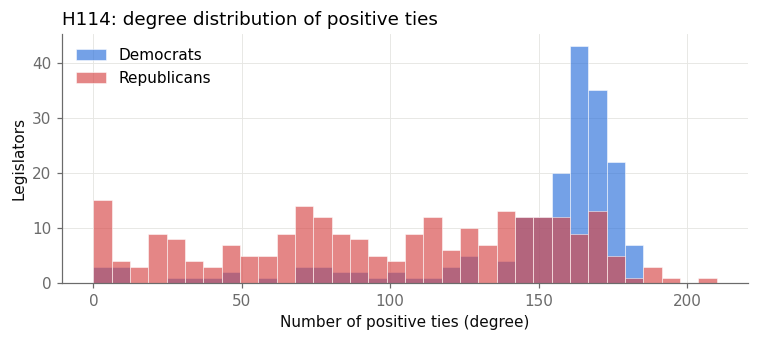

median degree: {'D': 163, 'R': 106}


In [6]:
deg_pos = np.array([d for _, d in G_pos.degree()])
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, deg_pos.max(), 35)
for p in ["D", "R"]:
    ax.hist(deg_pos[party == p], bins=bins, color=PARTY_COLORS[p], alpha=0.65,
            label={"D": "Democrats", "R": "Republicans"}[p], edgecolor="white", linewidth=0.5)
ax.set_xlabel("Number of positive ties (degree)"); ax.set_ylabel("Legislators")
ax.set_title(f"{SESSION}: degree distribution of positive ties", loc="left")
ax.legend(); plt.tight_layout(); plt.show()
print("median degree:", {p: int(np.median(deg_pos[party == p])) for p in ["D", "R"]})

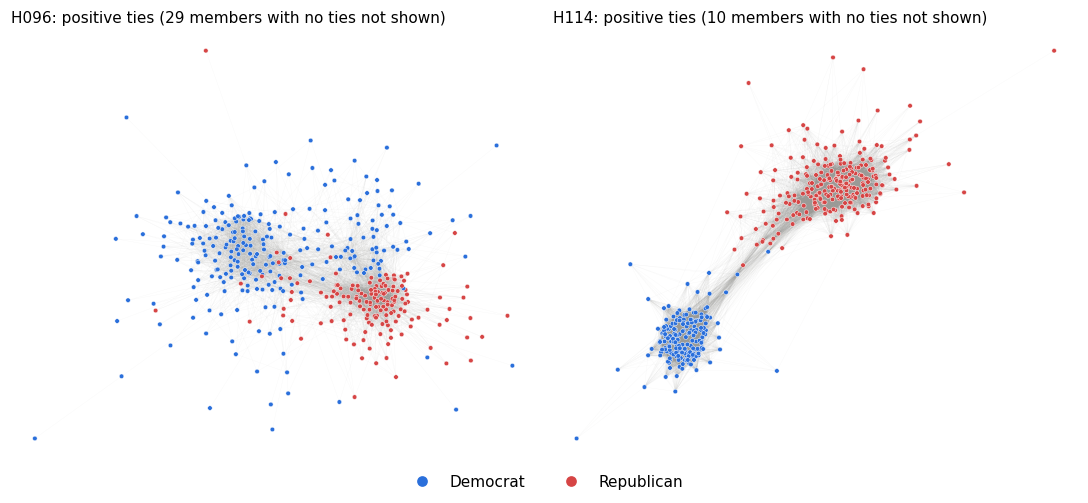

In [7]:
def sociogram(session, ax, seed=19880106):
    nd, ed = sheets[f"nodes_{session}"], sheets[f"edges_{session}"]
    g = nx.Graph(); g.add_nodes_from(range(len(nd)))
    g.add_edges_from(ed.loc[ed.sign == 1, ["source", "target"]].itertuples(index=False))
    isolates = list(nx.isolates(g)); g.remove_nodes_from(isolates)   # plot connected members only
    pos = nx.spring_layout(g, seed=seed)                  # force-directed layout
    from matplotlib.collections import LineCollection
    segs = [(pos[u], pos[v]) for u, v in g.edges()]
    ax.add_collection(LineCollection(segs, colors="#9a9a96", linewidths=0.2, alpha=0.08))
    keep_nodes = list(g.nodes())
    xy = np.array([pos[i] for i in keep_nodes])
    cols = [PARTY_COLORS.get(nd.party_session[i], MUTED) for i in keep_nodes]
    ax.scatter(xy[:, 0], xy[:, 1], s=9, c=cols, edgecolors="white", linewidths=0.3, zorder=3)
    ax.set_title(f"{session}: positive ties ({len(isolates)} members with no ties not shown)",
                 loc="left", fontsize=10); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
sociogram("H096", axes[0]); sociogram("H114", axes[1])
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=PARTY_COLORS[p], label=l)
                    for p, l in [("D", "Democrat"), ("R", "Republican")]],
           loc="lower center", ncol=2)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

> R equivalent. `igraph::graph_from_data_frame()`, `igraph::transitivity()`, `sna::gden()`; sociograms with `plot.network()` or `ggraph`. Neal built the signed backbones with `backbone::sdsm()`.

## 4. What a graph neural network does

### 4.1 Why not standard machine learning?

A standard learner (a logit, a random forest, a neural network) takes a fixed-length row of features for each observation. A network does not fit that mold: nodes have different numbers of neighbors, neighbors have no natural order, and observations are not independent. The usual workaround is to compute network statistics by hand, such as degree, centrality or shared partners, and feed them to a random forest. Section 5 does exactly this as a benchmark. GNNs instead learn the features from the graph during training.

### 4.2 Neural network refresher

One neural network layer transforms an input vector $x$ into a new representation:

$$h = \sigma(Wx + b),$$

where the weights $W$ and $b$ are learned and $\sigma$ is a nonlinearity, such as ReLU, $\sigma(z) = \max(0, z)$. Stacking layers gives a flexible nonlinear function. One layer with a sigmoid output is logistic regression: $\Pr(y = 1) = \text{logistic}(w^\top x + b)$. Section 5.2 checks this numerically.

Training minimizes a loss (squared error, or cross-entropy, which is the negative log-likelihood of a logit) by gradient descent, with backpropagation computing the gradient for every weight. The data are split three ways:

- training data fit the weights;
- validation data choose the design: number of layers, width, learning rate and when to stop training;
- test data are used once, to report performance.

### 4.3 The core idea: message passing

A GNN gives every node a vector of numbers (its representation or embedding) and updates it by passing messages along ties. In each layer, every node collects messages from its neighbors and updates its own vector. After one layer a node knows about its neighbors; after two layers, also about its neighbors' neighbors.

The general message passing neural network (Wu et al. 2021, Eq. 21) is

$$
h_v^{(k)} = U_k\!\Big(h_v^{(k-1)},\ \sum_{u \in N(v)} M_k\big(h_v^{(k-1)}, h_u^{(k-1)}, x^e_{vu}\big)\Big),
$$

where $M_k$ forms a message from each neighbor $u$ (and can use edge features $x^e_{vu}$), the sum collects them, and $U_k$ updates node $v$. The sum ignores neighbor order, and the same weights apply at every node. The final $h_v$ is an embedding of $v$ used for prediction.

The graph convolutional network (GCN; Kipf and Welling 2017) is the most common special case:

$$
H^{(l+1)} = \sigma\!\left(\tilde D^{-1/2}\, \tilde A\, \tilde D^{-1/2}\; H^{(l)}\; W^{(l)}\right),
$$

with $\tilde A = A + I$ the adjacency matrix with self-loops, $\tilde D$ its diagonal degree matrix, $H^{(0)} = X$ the node features (here party, state and DW-NOMINATE) and $W^{(l)}$ learned and shared across nodes. Neighbor $u$'s weight in $v$'s average is $1/\sqrt{\tilde d_v \tilde d_u}$.

Connection to network autocorrelation. The model from 11/10 is $y = \rho W y + X\beta + \varepsilon$. A one-layer linear GCN, $\tilde D^{-1/2}\tilde A\tilde D^{-1/2} X W$, is a regression on a spatially lagged $X$, with a particular normalized weight matrix. The GCN adds nonlinearity, multiple hops (lags of lags) and many features. It gives up an interpretable dependence parameter like $\rho$.

Two variants used below.

- Graph attention network (GAT; Veličković et al. 2018): $h_v^{(l+1)} = \sigma\big(\sum_{u\in N(v)\cup\{v\}} \alpha_{vu} W h_u^{(l)}\big)$. Where the GCN fixes each neighbor's weight by degree, GAT learns the weights $\alpha_{vu}$ from the features of $v$ and $u$; they sum to one over $v$'s neighbors. We use four attention "heads" and average them.
- GraphSAGE (Hamilton, Ying and Leskovec 2017): keeps a node's own vector separate from its neighbors' average, $h_v' = \sigma\big(W_1 h_v + W_2 \cdot \text{mean}_{u\in N(v)} h_u\big)$. As proposed, it samples a fixed number of neighbors per node, which is what lets it scale to very large graphs. With 440 legislators we can afford to average over all neighbors.

In the taxonomy of Wu et al. (2021), GCN, GAT and GraphSAGE are spatial convolutional GNNs (a fixed stack of neighbor-aggregation layers), and Sections 5 and 6 wrap them in graph autoencoders. The spatio-temporal GNNs of the Brandt et al. (2022) case study add time-series layers; Section 6 handles time more simply, by training on one Congress and predicting the next.

### 4.4 One GCN layer by hand

To show there is no magic inside `GCNConv`, the next cell computes one layer with plain matrix algebra and checks it against PyTorch Geometric using the same weights.

In [8]:
# Node features: Republican indicator, two DW-NOMINATE dimensions, state dummies
def node_features(nd, use_nominate=True):
    cols = [(nd.party_session == "R").to_numpy(float)[:, None]]
    if use_nominate:
        cols.append(nd[["nominate_dim1", "nominate_dim2"]].to_numpy())
    cols.append(pd.get_dummies(pd.Categorical(nd.state, categories=ALL_STATES)).to_numpy(float))
    return torch.tensor(np.hstack(cols), dtype=torch.float)

X = node_features(nodes)
print("feature matrix:", tuple(X.shape), "(legislators x features)")

# --- by hand -------------------------------------------------------------
A = torch.zeros(n, n); A[ei_pos[0], ei_pos[1]] = 1.0      # adjacency matrix
A_tilde = A + torch.eye(n)                                # add self-loops
d_inv_sqrt = A_tilde.sum(1).pow(-0.5)                     # \tilde D^{-1/2}
A_norm = d_inv_sqrt[:, None] * A_tilde * d_inv_sqrt[None, :]

set_seed(19880106)
layer = GCNConv(X.size(1), 4)                              # PyG layer with 4 output dimensions
W, b = layer.lin.weight.detach().T, layer.bias.detach()    # reuse its random weights
H_by_hand = A_norm @ X @ W + b                             # one layer, before the nonlinearity

# --- PyTorch Geometric -----------------------------------------------------
H_pyg = layer(X, ei_pos).detach()
print("largest difference between the two:", float((H_by_hand - H_pyg).abs().max()))

feature matrix: (440, 53) (legislators x features)
largest difference between the two: 1.6391277313232422e-07


The two agree up to rounding error. Everything else in this tutorial is this operation, stacked and trained.

### 4.5 What one round of message passing tells a node

Apply an aggregation to a single feature, the Republican indicator, with no weights at all. To keep the numbers readable, this cell uses a plain average ($\tilde D^{-1}\tilde A$, which GraphSAGE's mean aggregator also uses) rather than the GCN's symmetric version; each legislator's new value is then exactly the Republican share among themselves and their collaborators.

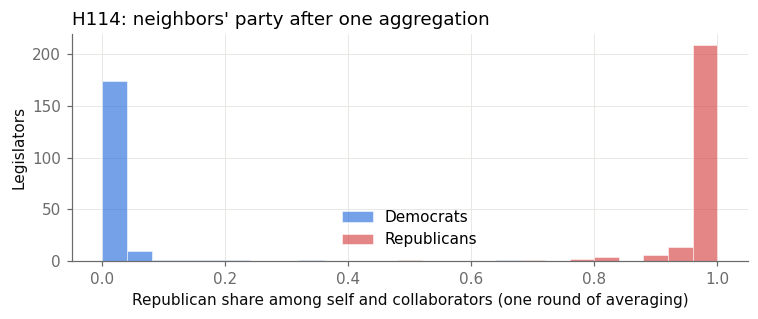

In [9]:
A_mean = A_tilde / A_tilde.sum(1, keepdim=True)            # row-normalized: a plain average
rep_share = (A_mean @ torch.tensor(is_rep, dtype=torch.float)).numpy()
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0, 1, 26)
for p in ["D", "R"]:
    ax.hist(rep_share[party == p], bins=bins, color=PARTY_COLORS[p], alpha=0.65,
            label={"D": "Democrats", "R": "Republicans"}[p], edgecolor="white", linewidth=0.5)
ax.set_xlabel("Republican share among self and collaborators (one round of averaging)")
ax.set_ylabel("Legislators"); ax.legend()
ax.set_title(f"{SESSION}: neighbors' party after one aggregation", loc="left")
plt.tight_layout(); plt.show()

The two parties separate almost completely after a single aggregation. This is why a GNN can predict party from ties (Section 7), and it is also a warning: in a network this polarized, much of what a GNN "learns" is that collaborators share a party.

### 4.6 Layers, hops and over-smoothing

$K$ layers let information travel $K$ hops, so why not use many? Because each graph convolution pulls neighbors' representations together, and with many layers all nodes converge toward the same representation (Wu et al. 2021, Sec. IX). Repeat the averaging above many times and watch the two parties' average Republican share:

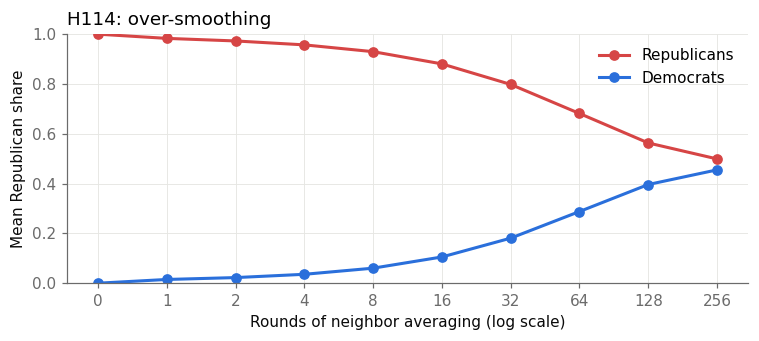

 rounds  Democrats  Republicans
      0      0.000        1.000
      1      0.015        0.983
      2      0.023        0.973
      4      0.036        0.957
      8      0.060        0.930
     16      0.105        0.881
     32      0.181        0.798
     64      0.288        0.681
    128      0.396        0.563
    256      0.455        0.499


In [10]:
x = torch.tensor(is_rep, dtype=torch.float)
rounds, d_mean, r_mean = [], [], []
for k in range(257):
    if k in (0, 1, 2, 4, 8, 16, 32, 64, 128, 256):
        rounds.append(k); d_mean.append(x[party == "D"].mean().item()); r_mean.append(x[party == "R"].mean().item())
    x = A_mean @ x                                        # one more round of averaging

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(rounds, r_mean, "o-", color=PARTY_COLORS["R"], lw=2, ms=6, label="Republicans")
ax.plot(rounds, d_mean, "o-", color=PARTY_COLORS["D"], lw=2, ms=6, label="Democrats")
ax.set_xscale("symlog", base=2); ax.set_xticks(rounds); ax.set_xticklabels(rounds)
ax.set_ylim(0, 1); ax.set_xlabel("Rounds of neighbor averaging (log scale)")
ax.set_ylabel("Mean Republican share"); ax.legend()
ax.set_title(f"{SESSION}: over-smoothing", loc="left")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"rounds": rounds, "Democrats": np.round(d_mean, 3), "Republicans": np.round(r_mean, 3)}).to_string(index=False))

After a few rounds the parties are still far apart, but with enough rounds the information that distinguishes them is averaged away. (In this House the convergence is slow, because so few ties cross the aisle: polarization itself slows the mixing.) This is why most applied GNNs use two to four layers, chosen on the validation set. Section 5.4 makes that choice.

## 5. Link prediction: who collaborates with whom?

### 5.1 Setting up a fair test

We hide 10% of positive ties as a test set and another 10% as a validation set. Models are trained on the remaining 80%. Message passing also uses only those training ties, so no model peeks at the ties it is asked to predict.

At test time each model scores the hidden ties together with an equal number of randomly drawn non-ties. With a rare outcome, accuracy misleads, so we use three summaries:

- AUC (area under the ROC curve): the probability that a randomly chosen hidden tie gets a higher score than a randomly chosen non-tie. 0.5 is guessing; 1 is perfect. Higher is better.
- AP (average precision): the average share of true ties among the top-ranked pairs, across all cutoffs. Higher is better.
- Log loss: $-\frac{1}{m}\sum [y\log p + (1-y)\log(1-p)]$, a proper scoring rule. AUC and AP only judge whether ties are ranked above non-ties; log loss also judges whether the predicted probabilities are right, and it punishes confident mistakes heavily. Lower is better. (On this balanced test set, always predicting 0.5 gives log loss 0.693.)

We repeat the whole exercise with `N_SPLITS` random splits and report the mean and standard deviation.

> This hold-out logic is standard in machine learning but not in ERGM-style inference. It treats the hidden ties as a random sample of dyads even though dyads in a network are dependent. It is a sensible way to compare predictive performance, but it is not a test of a hypothesis. Section 6 uses the alternative the lecture recommends: holding out a later period.

In [11]:
data = torch_geometric.data.Data(x=X, edge_index=ei_pos, num_nodes=n)

def split_links(data, seed):
    set_seed(seed)
    splitter = RandomLinkSplit(num_val=0.10, num_test=0.10, is_undirected=True,
                               add_negative_train_samples=False, split_labels=True)
    return splitter(data)          # train, validation, test views of the same network

def scores(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p), "log loss": log_loss(y, p)}

train, val, test = split_links(data, seed=19880106)
print("training ties (both directions):", train.edge_index.size(1))
print("validation ties / non-ties:", val.pos_edge_label_index.size(1), "/", val.neg_edge_label_index.size(1))
print("test ties / non-ties:      ", test.pos_edge_label_index.size(1), "/", test.neg_edge_label_index.size(1))

training ties (both directions): 42182
validation ties / non-ties: 2636 / 2636
test ties / non-ties:       2636 / 2636


### 5.2 Simple benchmarks: dyadic logits and a random forest

"Always compare to a simple benchmark". The first benchmark is a logit on dyad covariates: same party, same state, and the absolute difference in each DW-NOMINATE dimension. This is exactly a dyad-independent ERGM, `edges + nodematch("party") + nodematch("state") + absdiff("nominate1") + absdiff("nominate2")`.

Two richer versions add endogenous network information computed from the training ties only:

- + degree: the sum of the two legislators' log degrees, a crude version of sociality effects (ERGM `gwdegree`, the sender/receiver effects in AME).
- + shared partners: the log number of collaborators the two legislators have in common, i.e. triadic closure (ERGM `gwesp`).

The last benchmark is the "standard machine learning" workaround from Section 4.1: a random forest fed the same covariates plus the hand-computed degree and shared-partner statistics. All benchmarks are fitted on the training ties and an equal number of sampled non-ties. The non-ties are never drawn from the validation or test pairs: a flexible model such as a random forest can memorize individual pairs, so letting a test pair into the training data, even labeled as a non-tie, would flatter it.

In [12]:
def dyad_covariates(nd, pairs, use_nominate=True, deg=None, shared=None):
    # pairs: 2 x m array of node ids; returns an m x k design matrix and column names
    i, j = pairs
    p, s = nd.party_session.values, nd.state.values
    nom = nd[["nominate_dim1", "nominate_dim2"]].to_numpy()
    cols = {"same party": p[i] == p[j], "same state": s[i] == s[j]}
    if use_nominate:
        cols["|diff| NOMINATE 1"] = np.abs(nom[i, 0] - nom[j, 0])
        cols["|diff| NOMINATE 2"] = np.abs(nom[i, 1] - nom[j, 1])
    if deg is not None:
        cols["log degree sum"] = np.log1p(deg[i]) + np.log1p(deg[j])
    if shared is not None:
        cols["log shared partners"] = np.log1p(shared[i, j])
    return np.column_stack(list(cols.values())).astype(float), list(cols)

def graph_stats(edge_index, num_nodes):
    # degree and number of shared partners for every pair, from a given set of ties
    deg = degree(edge_index[0], num_nodes).numpy()
    A_ = np.zeros((num_nodes, num_nodes)); A_[edge_index[0].numpy(), edge_index[1].numpy()] = 1
    return deg, A_ @ A_

def benchmark_specs(train, num_nodes, use_nominate=True):
    deg, shared = graph_stats(train.edge_index, num_nodes)
    return {"Logit: covariates": ("logit", dict(use_nominate=use_nominate)),
            "Logit: + degree": ("logit", dict(use_nominate=use_nominate, deg=deg)),
            "Logit: + degree + shared partners": ("logit", dict(use_nominate=use_nominate, deg=deg, shared=shared)),
            "Random forest: covariates + degree + shared partners":
                ("forest", dict(use_nominate=use_nominate, deg=deg, shared=shared))}

def fit_benchmark(kind, Z, y, seed):
    if kind == "logit":
        return LogisticRegression(max_iter=2000).fit(Z, y)
    return RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=seed).fit(Z, y)

def off_limits(train, val, test):
    # training ties plus every held-out pair (validation/test ties and non-ties), in both directions:
    # training non-ties are never drawn from these, so no held-out pair is ever seen in training
    held = torch.cat([val.pos_edge_label_index, val.neg_edge_label_index,
                      test.pos_edge_label_index, test.neg_edge_label_index], 1)
    return torch.cat([train.edge_index, held, held.flip(0)], 1)

def training_pairs(train, val, test, num_nodes, seed):
    set_seed(seed + 10_000)                     # a separate random stream from the split itself
    pos = train.pos_edge_label_index
    non = negative_sampling(off_limits(train, val, test), num_nodes=num_nodes, num_neg_samples=pos.size(1))
    y = np.r_[np.ones(pos.size(1)), np.zeros(non.size(1))]
    return np.hstack([pos.numpy(), non.numpy()]), y

def test_pairs(test):
    pos, non = test.pos_edge_label_index.numpy(), test.neg_edge_label_index.numpy()
    return np.hstack([pos, non]), np.r_[np.ones(pos.shape[1]), np.zeros(non.shape[1])]

Here is the richest logit fitted once, with `statsmodels` so we can read coefficients as in R's `glm()`.

In [13]:
pairs_tr, y_tr = training_pairs(train, val, test, n, seed=19880106)
kw = benchmark_specs(train, n)["Logit: + degree + shared partners"][1]
Z_tr, names = dyad_covariates(nodes, pairs_tr, **kw)
fit = sm.Logit(y_tr, sm.add_constant(Z_tr)).fit(disp=0)
print(pd.DataFrame({"coef": fit.params, "std. err.": fit.bse},
                   index=["intercept"] + names).round(3))

# For comparison: the same data with only the two match terms
Z_simple, names_simple = dyad_covariates(nodes, pairs_tr, use_nominate=False)
fit_simple = sm.Logit(y_tr, sm.add_constant(Z_simple)).fit(disp=0)
print("\nOnly party and state matching:")
print(pd.DataFrame({"coef": fit_simple.params, "std. err.": fit_simple.bse},
                   index=["intercept"] + names_simple).round(3))

                      coef  std. err.
intercept           -1.401      0.476
same party          -3.117      0.149
same state           3.852      0.158
|diff| NOMINATE 1   -5.203      0.220
|diff| NOMINATE 2   -0.917      0.096
log degree sum      -0.504      0.075
log shared partners  3.045      0.081

Only party and state matching:
             coef  std. err.
intercept  -4.184      0.065
same party  5.211      0.067
same state  1.875      0.091


Read these coefficients the way we read ERGM coefficients: each is conditional on all the others, and several of the variables overlap heavily.

- Ideological distance has a large negative coefficient: the further apart two legislators are on the first DW-NOMINATE dimension, the less likely they collaborate.
- Same party is negative in the full model, but strongly positive (about +5) when it appears with same state alone. That is not "co-partisans avoid each other." In the 114th House, co-partisans are ideologically close and share many collaborators, so ideological distance and shared partners already carry the party divide. The party coefficient in the full model only compares pairs with the same ideological distance and the same number of shared partners, a thin and unusual slice of the data.
- Shared partners is strongly positive (triadic closure). Degree turns negative once shared partners are included, because busy legislators mechanically share many partners; holding shared partners fixed, a pair of very active legislators is less remarkable.
- Same state is positive: delegation ties matter beyond party and ideology.

We can interpret signs and magnitudes at all, which we will not be able to do with the GNN. As in the 10/27 lecture, the standard errors assume independent dyads and are too small; read them as descriptive only.

A logit is a one-layer neural network. To make the refresher concrete, fit the same model as a single `torch` layer, $\text{logistic}(w^\top x + b)$, by minimizing cross-entropy, and compare the weights with the `statsmodels` coefficients:

In [14]:
Zt, yt = torch.tensor(Z_tr, dtype=torch.float64), torch.tensor(y_tr, dtype=torch.float64)
one_layer = torch.nn.Linear(Zt.size(1), 1).double()               # h = W x + b
opt = torch.optim.LBFGS(one_layer.parameters(), max_iter=5000, tolerance_grad=1e-10,
                        tolerance_change=1e-12, line_search_fn="strong_wolfe")
def closure():
    opt.zero_grad()
    loss = F.binary_cross_entropy_with_logits(one_layer(Zt).squeeze(1), yt)   # sigmoid + cross-entropy
    loss.backward(); return loss
for _ in range(5):
    opt.step(closure)
nn_coefs = np.r_[one_layer.bias.item(), one_layer.weight.detach().numpy().ravel()]
print(pd.DataFrame({"statsmodels logit": fit.params, "one-layer network": nn_coefs},
                   index=["intercept"] + names).round(3))

                     statsmodels logit  one-layer network
intercept                       -1.401             -1.401
same party                      -3.117             -3.117
same state                       3.852              3.852
|diff| NOMINATE 1               -5.203             -5.203
|diff| NOMINATE 2               -0.917             -0.917
log degree sum                  -0.504             -0.504
log shared partners              3.045              3.045


The weights match the logit coefficients. A GNN adds hidden layers and message passing on top of this.

> R equivalent. `glm(tie ~ same_party + same_state + absdiff1 + absdiff2, family = binomial)` on a dyad data frame, or `ergm(net ~ edges + nodematch("party") + nodematch("state") + absdiff("nominate1") + absdiff("nominate2"))`. The degree and shared-partner versions approximate `gwdegree` and `gwesp`, which a real ERGM estimates jointly with the dyad dependence. Random forests: `ranger::ranger()` or `randomForest::randomForest()`.

### 5.3 Graph autoencoders and latent space models

A graph autoencoder (GAE) has two parts:

- an encoder: two GNN layers (GCN, GraphSAGE or GAT) that map each legislator's features and neighborhood to an embedding $z_i$ (32 numbers);
- a decoder that scores a pair by the inner product of their embeddings (Wu et al. 2021, Eq. 32): $\Pr(y_{ij} = 1) = \sigma(z_i^\top z_j)$.

Compare the bilinear latent space model from 10/27: $\text{logit}\Pr(y_{ij} = 1) = x_{ij}^\top\beta + z_i^\top z_j$. The decoder is the same inner product, minus the covariate term. The key difference: in the LSM, $z_i$ is a parameter; in a GAE, it is a learned function of features and neighborhood.

| | Latent space model (10/27) | Graph autoencoder |
|---|---|---|
| positions $z_i$ | free parameters, one per node | a function of node features and neighbors |
| covariates | $x_{ij}^\top\beta$ in the linear predictor | enter through node features |
| estimation | MCMC, full likelihood | gradient descent on ties vs. sampled non-ties |
| uncertainty | posterior for every quantity | none by default |

Because the two are so close, we also fit a hybrid that uses the LSM's full linear predictor with GCN embeddings: $\text{logit}\Pr(y_{ij}=1) = \beta_0 + x_{ij}^\top\beta + z_i^\top z_j$, with the same four dyad covariates as the logit benchmark and $\beta$ learned along with the GCN weights.

Two more models complete the comparison. An MLP autoencoder has the same layers and decoder but never looks at the network, so it isolates what message passing adds. The GAT encoder lets the model learn how much to weight each neighbor.

Training minimizes cross-entropy for training ties against a fresh random set of non-ties in each step. Non-ties are never drawn from the held-out validation or test pairs, for the GNNs or for the benchmarks. Every 10 steps we compute validation AUC and keep the best model: the validation set chooses the stopping time.

In [15]:
class Encoder(torch.nn.Module):
    # features -> 64 hidden units -> ... -> 32-dimensional embedding
    def __init__(self, kind, in_dim, layers=2, hidden=64, out=32):
        super().__init__()
        self.kind = kind
        dims = [in_dim] + [hidden] * (layers - 1) + [out]
        make = {"GCN":       lambda a, b: GCNConv(a, b),
                "GraphSAGE": lambda a, b: SAGEConv(a, b),
                "GAT":       lambda a, b: GATConv(a, b, heads=4, concat=False),
                "MLP":       lambda a, b: torch.nn.Linear(a, b)}[kind]
        self.layers = torch.nn.ModuleList([make(a, b) for a, b in zip(dims[:-1], dims[1:])])

    def forward(self, x, edge_index):
        for k, layer in enumerate(self.layers):
            x = layer(x) if self.kind == "MLP" else layer(x, edge_index)   # MLP ignores the network
            if k < len(self.layers) - 1:
                x = F.relu(x)
        return x

class LinkModel(torch.nn.Module):
    # encoder + decoder: logit Pr(tie) = z_i'z_j  (+ b0 + x_ij'beta if covariates are used)
    def __init__(self, kind, in_dim, layers=2, n_cov=0):
        super().__init__()
        self.encoder = Encoder(kind, in_dim, layers)
        self.cov = torch.nn.Linear(n_cov, 1) if n_cov else None

    def score(self, z, pairs, cov=None):
        s = (z[pairs[0]] * z[pairs[1]]).sum(1)
        if self.cov is not None:
            s = s + self.cov(cov).squeeze(1)
        return s

def train_link_model(kind, train, val, nd, seed, layers=2, use_cov=False, use_nominate=True,
                     isolate=0.0, epochs=None, test=None):
    epochs = epochs or EPOCHS
    set_seed(seed)
    cov = (lambda pairs: torch.tensor(dyad_covariates(nd, np.asarray(pairs), use_nominate)[0],
                                      dtype=torch.float)) if use_cov else (lambda pairs: None)
    model = LinkModel(kind, train.x.size(1), layers, n_cov=4 if use_nominate else 2) if use_cov \
        else LinkModel(kind, train.x.size(1), layers)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    pos = train.pos_edge_label_index
    forbidden = off_limits(train, val, test) if test is not None else train.edge_index
    val_pairs = torch.cat([val.pos_edge_label_index, val.neg_edge_label_index], 1)
    y_val = np.r_[np.ones(val.pos_edge_label_index.size(1)), np.zeros(val.neg_edge_label_index.size(1))]
    best_auc, best_state = -1, None
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        mp = train.edge_index                                  # ties used for message passing
        if isolate > 0:                                         # Section 6: practice on "newcomers"
            cut = torch.rand(train.num_nodes) < isolate
            mp = mp[:, ~(cut[mp[0]] | cut[mp[1]])]
        z = model.encoder(train.x, mp)
        non = negative_sampling(forbidden, num_nodes=train.num_nodes, num_neg_samples=pos.size(1))
        logits = torch.cat([model.score(z, pos, cov(pos)), model.score(z, non, cov(non))])
        target = torch.cat([torch.ones(pos.size(1)), torch.zeros(non.size(1))])
        F.binary_cross_entropy_with_logits(logits, target).backward(); opt.step()
        if epoch % 10 == 0:                                     # early stopping on validation AUC
            model.eval()
            with torch.no_grad():
                z = model.encoder(val.x, val.edge_index)
                auc = roc_auc_score(y_val, model.score(z, val_pairs, cov(val_pairs)).numpy())
            if auc > best_auc:
                best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    model.cov_fn = cov
    return model, best_auc

def predict_links(model, x, edge_index, pairs, nd=None, use_nominate=True):
    # probabilities for the given pairs; nd supplies the dyad covariates of the hybrid model
    pairs = torch.as_tensor(np.asarray(pairs))
    cov = None
    if model.cov is not None:
        cov = torch.tensor(dyad_covariates(nd, pairs.numpy(), use_nominate)[0], dtype=torch.float)
    with torch.no_grad():
        return torch.sigmoid(model.score(model.encoder(x, edge_index), pairs, cov)).numpy()

### 5.4 Choosing depth on the validation set

Before the full comparison, use the validation set to choose the number of GCN layers. Only validation AUC is used here; the test set stays untouched.

In [16]:
depth = []
for L in [1, 2, 3, 4, 6]:
    _, best = train_link_model("GCN", train, val, nodes, seed=19880106, layers=L, test=test)
    depth.append((L, round(best, 4)))
pd.DataFrame(depth, columns=["GCN layers", "best validation AUC"])

,GCN layers,best validation AUC
0,1,0.9737
1,2,0.9758
2,3,0.9753
3,4,0.9730
4,6,0.9717


Two layers give the best validation AUC, with one and three layers close behind; four or more layers do worse, as the over-smoothing argument predicts. We use two layers for every GNN from here on.

### 5.5 Running the comparison

The next cell fits all nine models on `N_SPLITS` random splits. This is the slow step (several minutes).

In [17]:
GNN_SPECS = {   # name: (encoder, use LSM-style covariate term)
    "Autoencoder: MLP (no network)": ("MLP", False),
    "GNN: GCN": ("GCN", False),
    "GNN: GraphSAGE": ("GraphSAGE", False),
    "GNN: GAT": ("GAT", False),
    "GNN: GCN + covariates (LSM-style decoder)": ("GCN", True),
}

def run_link_prediction(X, nd=None, ei=None, seeds=None, use_nominate=True, gnn_names=None):
    nd = nodes if nd is None else nd
    ei = ei_pos if ei is None else ei
    seeds = range(N_SPLITS) if seeds is None else seeds
    gnn_names = list(GNN_SPECS) if gnn_names is None else gnn_names
    rows, m = [], len(nd)
    data = torch_geometric.data.Data(x=X, edge_index=ei, num_nodes=m)
    for seed in seeds:
        train, val, test = split_links(data, seed)
        pairs_te, y_te = test_pairs(test)
        pairs_tr, y_tr = training_pairs(train, val, test, m, seed)
        for name, (kind, kw) in benchmark_specs(train, m, use_nominate).items():
            clf = fit_benchmark(kind, dyad_covariates(nd, pairs_tr, **kw)[0], y_tr, seed)
            p = clf.predict_proba(dyad_covariates(nd, pairs_te, **kw)[0])[:, 1]
            rows.append({"split": seed, "model": name, **scores(y_te, p)})
        for name in gnn_names:
            kind, use_cov = GNN_SPECS[name]
            model, _ = train_link_model(kind, train, val, nd, seed, use_cov=use_cov, use_nominate=use_nominate,
                                        test=test)
            p = predict_links(model, test.x, test.edge_index, pairs_te, nd, use_nominate)
            rows.append({"split": seed, "model": name, **scores(y_te, p)})
    return pd.DataFrame(rows)

def summarize(results):
    t = results.groupby("model").agg(AUC=("AUC", "mean"), AUC_sd=("AUC", "std"), AP=("AP", "mean"),
                                     log_loss=("log loss", "mean"), log_loss_sd=("log loss", "std"))
    return t.sort_values("AUC", ascending=False).round(3)

t0 = time.time()
lp_results = run_link_prediction(X)
print(f"done in {time.time() - t0:.0f} seconds")
lp_table = summarize(lp_results)
lp_table

done in 207 seconds


,AUC,AUC_sd,AP,log_loss,log_loss_sd
model,,,,,
GNN: GCN + covariates (LSM-style decoder),0.983,0.001,0.982,0.171,0.006
Logit: + degree + shared partners,0.981,0.001,0.979,0.170,0.002
Random forest: covariates + degree + shared partners,0.981,0.001,0.979,0.169,0.004
GNN: GraphSAGE,0.976,0.001,0.974,0.265,0.009
GNN: GCN,0.975,0.001,0.972,0.289,0.010
Logit: + degree,0.974,0.000,0.972,0.207,0.001
GNN: GAT,0.966,0.003,0.959,0.303,0.019
Autoencoder: MLP (no network),0.962,0.002,0.957,0.312,0.009
Logit: covariates,0.902,0.006,0.866,0.348,0.010


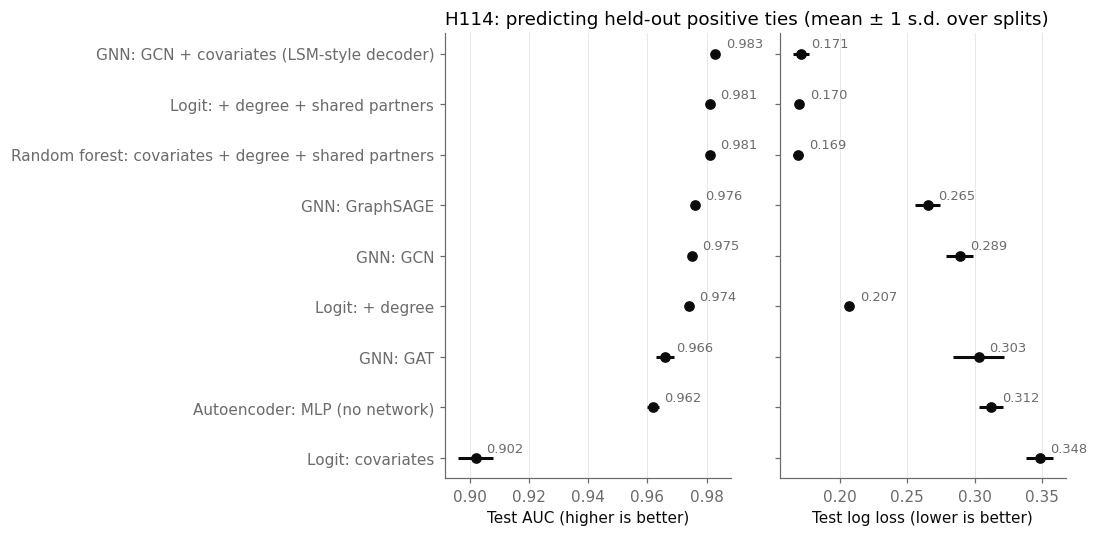

In [18]:
def plot_metrics(table, title):
    t = table.iloc[::-1]                       # best AUC at the top
    y = np.arange(len(t))
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.42 * len(t) + 1.2), sharey=True)
    for ax, col, sd, lab in [(axes[0], "AUC", "AUC_sd", "Test AUC (higher is better)"),
                             (axes[1], "log_loss", "log_loss_sd", "Test log loss (lower is better)")]:
        ax.errorbar(t[col], y, xerr=t[sd], fmt="o", color=INK, ms=6, capsize=0, lw=2)
        for yi, v in zip(y, t[col]):
            ax.annotate(f"{v:.3f}", (v, yi), xytext=(7, 4), textcoords="offset points", color=MUTED, fontsize=8.5)
        ax.set_xlabel(lab); ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y); axes[0].set_yticklabels(t.index)
    axes[0].set_title(title, loc="left")
    plt.tight_layout(); plt.show()

plot_metrics(lp_table, f"{SESSION}: predicting held-out positive ties (mean ± 1 s.d. over splits)")

### 5.6 Reading the comparison

- Covariates alone get far. Party, state and ideology give the plain logit an AUC near 0.90: in a House this polarized, "same party and ideologically close" is most of the story.
- Message passing helps over features alone. The MLP autoencoder uses the same features as the GNNs but ignores the network; the GCN and GraphSAGE beat it clearly. The gain comes from seeing who a legislator already collaborates with. GAT, despite its learned neighbor weights, does no better than the simpler GCN here.
- The hand-made workaround beats the plain GNNs. The random forest with degree and shared partners, the "standard machine learning" workaround from Section 4.1, ranks held-out ties better than the GCN, GraphSAGE or GAT, and so does the logit with the same two statistics (both about 0.981, against 0.975–0.976). Much of what a GNN learns here is what ERGMs have long modeled with a few interpretable statistics: activity and closure.
- The metric changes the winner. Compare the plain GCN and GraphSAGE with the logit that adds only degree. By AUC, the GNNs come out slightly ahead. By log loss, they are clearly worse (about 0.27–0.29, against 0.21): their inner-product probabilities are poorly calibrated, often too confident in the wrong direction, while a logit fitted by maximum likelihood produces calibrated probabilities. This is the same lesson as Brandt et al. (2022), where MSE and CRPS crowned different models.
- Combining the LSM and the GNN is the best or tied for best on every metric. The hybrid with the LSM's linear predictor, $\beta_0 + x_{ij}^\top\beta + z_i^\top z_j$, has the highest AUC, and its log loss ties the two best benchmarks. The covariate term handles the well-understood part (party, state, ideology) and calibrates the probabilities, and the GCN embeddings pick up the network structure.

The point is not GNNs win or GNNs lose, but always compare with the strongest simple benchmark you can specify, on more than one metric.

## 6. Holding out a later period: forecasting the next Congress

A random split hides ties within one Congress. A tougher and more realistic test holds out a later period: train on the 113th House (2013–14) and predict every pair in the 114th House (2015–16).

This also separates the two kinds of prediction from the lecture:

- Transductive: the nodes were seen in training; predict their unobserved ties. Here: pairs of returning members, who already have 113th-House ties.
- Inductive: predict for nodes never seen in training. Here: any pair involving a freshman, who has no 113th-House ties. Inductive prediction must work from features and neighborhoods, not node identities.

Design. Every model is trained only on 113th-House data (with a random validation split inside the 113th for early stopping). To predict the 114th, each model sees the 114th members' features and the 113th-House ties among returning members; freshmen are isolated nodes. Every one of the roughly 96,000 pairs is scored.

Models.

- Persistence: predict a tie in the 114th exactly where there was one in the 113th, the natural simple benchmark for panel data (like the stability term in a temporal ERGM).
- Logit: covariates and Logit: + degree + shared partners, trained on the 113th, with degree and shared partners computed from the 113th-House ties.
- GraphSAGE, trained as in Section 5.
- GraphSAGE, trained with isolated nodes: during training, a random 15% of legislators are cut off from message passing in each step, so the model practices predicting for nodes that have features but no observed ties, exactly the situation of a freshman.

In [19]:
prev, cur = "H113", "H114"
nd_prev, nd_cur = sheets[f"nodes_{prev}"], sheets[f"nodes_{cur}"]
ed_prev, ed_cur = sheets[f"edges_{prev}"], sheets[f"edges_{cur}"]
n_prev, n_cur = len(nd_prev), len(nd_cur)
ei_prev = edge_index_from(ed_prev[ed_prev.sign == 1], n_prev)
X_prev, X_cur = node_features(nd_prev), node_features(nd_cur)

# Map 113th-House ties onto 114th-House node ids (returning members only), using ICPSR ids
to_cur = dict(zip(nd_cur.icpsr, nd_cur.node_id))
icpsr_prev = nd_prev.icpsr.to_numpy()
src, dst = icpsr_prev[ei_prev[0].numpy()], icpsr_prev[ei_prev[1].numpy()]
both = np.array([a in to_cur and b in to_cur for a, b in zip(src, dst)])
ei_lag = torch.tensor([[to_cur[a] for a in src[both]], [to_cur[b] for b in dst[both]]], dtype=torch.long)
returning = nd_cur.icpsr.isin(nd_prev.icpsr).to_numpy()

# Every pair in the 114th House, its outcome, and whether it involves a freshman
iu, ju = np.triu_indices(n_cur, k=1)
all_pairs = np.vstack([iu, ju])
A_cur = np.zeros((n_cur, n_cur))
A_cur[ed_cur.loc[ed_cur.sign == 1, "source"], ed_cur.loc[ed_cur.sign == 1, "target"]] = 1
y_cur = np.maximum(A_cur, A_cur.T)[iu, ju]
pair_returning = returning[iu] & returning[ju]
print(f"114th House: {returning.sum()} returning members, {(~returning).sum()} freshmen")
print(f"pairs: {pair_returning.sum()} between returning members, {(~pair_returning).sum()} involving a freshman")
print(f"share of pairs tied: {y_cur.mean():.3f}")

114th House: 375 returning members, 65 freshmen
pairs: 70125 between returning members, 26455 involving a freshman
share of pairs tied: 0.273


In [20]:
def run_forecast(seeds=None):
    seeds = range(N_SPLITS) if seeds is None else seeds
    deg_lag, shared_lag = graph_stats(ei_lag, n_cur)
    A_lag = np.zeros((n_cur, n_cur)); A_lag[ei_lag[0].numpy(), ei_lag[1].numpy()] = 1
    rows = []
    data_prev = torch_geometric.data.Data(x=X_prev, edge_index=ei_prev, num_nodes=n_prev)
    for seed in seeds:
        train_p, val_p, test_p = split_links(data_prev, seed)     # validation split inside the 113th
        pairs_tr, y_tr = training_pairs(train_p, val_p, test_p, n_prev, seed)
        deg_p, shared_p = graph_stats(train_p.edge_index, n_prev)
        preds = {"Persistence (tie in the 113th)": A_lag[iu, ju]}
        for name, kw_prev, kw_cur in [
                ("Logit: covariates", {}, {}),
                ("Logit: + degree + shared partners", dict(deg=deg_p, shared=shared_p),
                 dict(deg=deg_lag, shared=shared_lag))]:
            clf = LogisticRegression(max_iter=2000).fit(dyad_covariates(nd_prev, pairs_tr, **kw_prev)[0], y_tr)
            preds[name] = clf.predict_proba(dyad_covariates(nd_cur, all_pairs, **kw_cur)[0])[:, 1]
        for name, iso in [("GNN: GraphSAGE", 0.0), ("GNN: GraphSAGE, trained with isolated nodes", 0.15)]:
            model, _ = train_link_model("GraphSAGE", train_p, val_p, nd_prev, seed, isolate=iso, test=test_p)
            preds[name] = predict_links(model, X_cur, ei_lag, all_pairs)
        for name, p in preds.items():
            rows.append({"split": seed, "model": name,
                         "AUC, all pairs": roc_auc_score(y_cur, p),
                         "AUC, returning pairs": roc_auc_score(y_cur[pair_returning], p[pair_returning]),
                         "AUC, pairs with a freshman": roc_auc_score(y_cur[~pair_returning], p[~pair_returning]),
                         "AP, all pairs": average_precision_score(y_cur, p)})
    return pd.DataFrame(rows)

t0 = time.time()
fc_results = run_forecast()
print(f"done in {time.time() - t0:.0f} seconds")
fc_table = fc_results.drop(columns="split").groupby("model").mean().sort_values("AUC, all pairs", ascending=False).round(3)
fc_table

done in 68 seconds


,"AUC, all pairs","AUC, returning pairs","AUC, pairs with a freshman","AP, all pairs"
model,,,,
"GNN: GraphSAGE, trained with isolated nodes",0.940,0.950,0.901,0.837
Logit: covariates,0.901,0.911,0.876,0.711
GNN: GraphSAGE,0.897,0.945,0.671,0.799
Logit: + degree + shared partners,0.893,0.954,0.754,0.790
Persistence (tie in the 113th),0.795,0.881,0.500,0.620


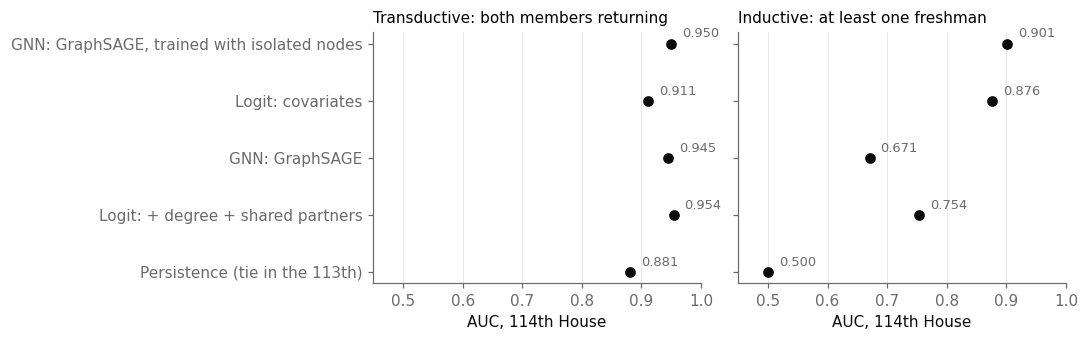

In [21]:
t = fc_table.iloc[::-1]
y = np.arange(len(t))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, col, lab in [(axes[0], "AUC, returning pairs", "Transductive: both members returning"),
                     (axes[1], "AUC, pairs with a freshman", "Inductive: at least one freshman")]:
    ax.scatter(t[col], y, color=INK, s=36, zorder=3)
    for yi, v in zip(y, t[col]):
        ax.annotate(f"{v:.3f}", (v, yi), xytext=(7, 4), textcoords="offset points", color=MUTED, fontsize=8.5)
    ax.set_xlim(0.45, 1.0); ax.set_title(lab, loc="left", fontsize=10)
    ax.set_xlabel("AUC, 114th House"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(y); axes[0].set_yticklabels(t.index)
plt.tight_layout(); plt.show()

Reading the forecast.

- For returning members, last Congress's network is very informative. Persistence alone, a single 0/1 rule, reaches an AUC near 0.88 on pairs of returning members, close to the covariate logit (0.91), which uses party, state and ideology but no network. Persistence's AUC is capped because a 0/1 rule cannot rank pairs within the large groups of tied and untied pairs. The models that combine the 113th-House network with covariates do best here, around 0.95: the logit with degree and shared partners and both GraphSAGE models are within a few thousandths of each other.
- For freshmen, persistence has nothing to say (AUC 0.5), and a plain GNN does poorly. GraphSAGE trained the usual way reaches only about 0.67 on pairs involving a freshman, well below the covariate logit (about 0.88). During training every legislator had neighbors; at prediction time a freshman has none, a situation the model never saw. The degree and shared-partner logit is hurt for the same reason: a freshman's degree of zero looks like a legislator who never collaborates.
- Train the way you will predict. Cutting random legislators off from message passing during training fixes the problem: the same GraphSAGE model reaches about 0.90 on pairs with a freshman, ahead of every benchmark, while staying near the top for returning members. It is the best model overall. Inductive prediction must work from features and neighborhoods, not node identities, and the model has to be trained for it.

The same logic underlies the inductive case in the lecture, predicting the behavior of a new armed group (Zawad et al. 2025): the model must have learned how features and the neighbors a node does have translate into predictions.

> R equivalent. A lagged-tie logit is a simple temporal ERGM; see `tergm::tergm()` or `btergm::btergm()` with a `memory()` (stability) term.

## 7. Node classification: recovering party from ties alone

Now a node-level task. Hide the party of almost every legislator and reveal it for only k Democrats and k Republicans. Can the positive-tie network alone recover the rest? This is transductive: the whole graph is seen in training, and we predict unobserved labels.

To make sure only the network is used, the input features are an identity matrix: each legislator gets a unique indicator and nothing else, no party, no ideology, no state. A two-layer GCN maps that through the network to a probability of being Republican and is trained on the 2k labeled legislators. This is the semi-supervised setup of Kipf and Welling (2017).

The baseline is label propagation: start from the labeled legislators and repeatedly set every other legislator's party score to the average of their neighbors' scores. This is the logic of network autocorrelation from 11/10 (neighbors' outcomes predict yours) with no covariates.

In [22]:
keep = np.isin(party, ["D", "R"])             # the target is D vs. R
y_party = torch.tensor(is_rep, dtype=torch.long)

class GCNClassifier(torch.nn.Module):
    def __init__(self, in_dim, hidden=16):
        super().__init__()
        self.l1, self.l2 = GCNConv(in_dim, hidden), GCNConv(hidden, 2)
    def forward(self, x, edge_index):
        h = F.dropout(F.relu(self.l1(x, edge_index)), p=0.5, training=self.training)
        return self.l2(h, edge_index)              # two scores: Democrat, Republican

def labeled_mask(k, seed):
    g = np.random.default_rng(seed)
    mask = np.zeros(n, dtype=bool)
    for p in ["D", "R"]:
        mask[g.choice(np.where(party == p)[0], size=k, replace=False)] = True
    return torch.tensor(mask)

def label_propagation(edge_index, labeled, iters=20):
    A_ = torch.zeros(n, n); A_[edge_index[0], edge_index[1]] = 1
    f = torch.zeros(n, 2); f[labeled, y_party[labeled]] = 1
    start = f.clone()
    for _ in range(iters):
        f = A_ @ f                                  # sum neighbors' scores
        f = f / f.sum(1, keepdim=True).clamp(min=1e-9)
        f[labeled] = start[labeled]                 # labeled legislators keep their party
    return f.argmax(1)

def run_node_classification(edge_index, ks=(1, 5, 20), seeds=range(5)):
    rows, last = [], None
    I = torch.eye(n)                                # identity features: network only
    for k in ks:
        for seed in seeds:
            labeled = labeled_mask(k, seed)
            set_seed(seed)
            model = GCNClassifier(n)
            opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
            for _ in range(200):
                model.train(); opt.zero_grad()
                F.cross_entropy(model(I, edge_index)[labeled], y_party[labeled]).backward(); opt.step()
            model.eval()
            with torch.no_grad():
                pred = model(I, edge_index).argmax(1)
            lp = label_propagation(edge_index, labeled)
            target = (~labeled) & torch.tensor(keep)
            rows.append((k, seed, (pred[target] == y_party[target]).float().mean().item(),
                         (lp[target] == y_party[target]).float().mean().item()))
            if k == 5 and seed == 0:
                last = (pred, labeled)
    res = pd.DataFrame(rows, columns=["labeled per party", "seed", "GCN", "Label propagation"])
    return res.groupby("labeled per party")[["GCN", "Label propagation"]].mean().round(3), last

nc_table, (pred_k5, labeled_k5) = run_node_classification(ei_pos)
print("Accuracy on unlabeled legislators (mean of 5 random label draws)")
nc_table

Accuracy on unlabeled legislators (mean of 5 random label draws)


,GCN,Label propagation
labeled per party,,
1,0.882,0.868
5,0.984,0.978
20,0.987,0.979


With only five labeled legislators per party, the GCN recovers the party of nearly every other member, and it does a little better than label propagation. Even one labeled legislator per party gets most of the House right. Collaboration in the 114th House is almost a perfect map of party.

The interesting cases are the errors. Below are the legislators the GCN misclassified in one run (five labels per party), with their degree and DW-NOMINATE score.

In [23]:
wrong = ((pred_k5 != y_party) & ~labeled_k5).numpy() & keep
cols = ["neal_label", "party_session", "nominate_dim1"]
errors = nodes.loc[wrong, cols].assign(positive_ties=deg_pos[wrong],
                                       predicted=np.where(pred_k5.numpy()[wrong] == 1, "R", "D"))
party_median_nom = nodes.groupby("party_session").nominate_dim1.median().round(3).to_dict()
print("party medians of DW-NOMINATE dim 1:", party_median_nom)
print("median number of positive ties:", int(np.median(deg_pos)))
errors.sort_values("nominate_dim1")

party medians of DW-NOMINATE dim 1: {'D': -0.396, 'R': 0.49}
median number of positive ties: 142


,neal_label,party_session,nominate_dim1,positive_ties,predicted
439,"Evans, D. (PA-D)",D,-0.473,0,R
250,"Hanabusa, C. (HI-D)",D,-0.370,0,R
93,"Peterson, C. (MN-D)",D,-0.148,81,R


The errors fall into two recognizable groups (exact names can shift with which legislators happen to be labeled):

- Members the network barely observes. Dwight Evans and Colleen Hanabusa were sworn in after special elections in November 2016, at the very end of the session. They have no positive ties at all, so the GCN has nothing to go on and falls back on a near guess.
- Cross-pressured moderates. Collin Peterson, a prominent Blue Dog Democrat, sits far to the right of his party's median DW-NOMINATE score, and enough of his collaboration is with Republicans that the GCN places him with them.

So the GCN's errors are substantively informative: they flag members whose collaboration does not follow party lines, and members the network barely observes. This is a useful habit with any predictive model: study the residuals.

> R equivalent. Label propagation: `igraph::cluster_label_prop()` (unsupervised) or a few lines of matrix code as above. The closest inferential analogue is a network autocorrelation model, `sna::lnam()`, with party as the outcome.

## 8. Try it yourself

Each exercise reuses the functions above. Try it first, then open the hint if you need it.

Exercise 1. A less polarized House. Rerun the notebook for the 96th House (1979–80). How do the link-prediction comparison and party recovery change compared with the 114th House? Why? (Section 6 does not change; it always uses the 113th and 114th Houses.)

<details><summary>Hint</summary>

Change one line in Section 2, then rerun the notebook (Runtime → Run all in Colab):

```python
SESSION = "H096"
```

</details>

Exercise 2. Learning from antagonism. Run the node-classification comparison using only the antagonistic ties. Does the GCN still recover party? Does label propagation? Why do they differ?

<details><summary>Hint</summary>

Pass the antagonistic ties (`ei_ant`) instead of the positive ties to the function from Section 7:

```python
nc_ant, _ = run_node_classification(ei_ant, ks=(5,))
nc_ant
```

</details>

Exercise 3. Without roll-call ideology. Drop DW-NOMINATE from the GNN node features and from the logit and forest covariates and rerun the link-prediction comparison. Which models lose the most? Why?

<details><summary>Hint</summary>

Build the features without NOMINATE and turn it off in the covariates. To save time, this runs the benchmarks and three of the autoencoders:

```python
X_no_nom = node_features(nodes, use_nominate=False)
lp_no_nom = run_link_prediction(X_no_nom, use_nominate=False,
                                gnn_names=["Autoencoder: MLP (no network)", "GNN: GCN",
                                           "GNN: GCN + covariates (LSM-style decoder)"])
summarize(lp_no_nom)
```

</details>

## 9. References

Lecture readings

- Brandt, Patrick T., Vito D'Orazio, Latifur Khan, Yi-Fan Li, Javier Osorio, and Marcus Sianan. 2022. "Conflict Forecasting with Event Data and Spatio-Temporal Graph Convolutional Networks." International Interactions 48(4): 800–822.
- Wu, Zonghan, Shirui Pan, Fengwen Chen, Guodong Long, Chengqi Zhang, and Philip S. Yu. 2021. "A Comprehensive Survey on Graph Neural Networks." IEEE Transactions on Neural Networks and Learning Systems 32(1): 4–24.
- Kipf, Thomas N., and Max Welling. 2017. "Semi-Supervised Classification with Graph Convolutional Networks." International Conference on Learning Representations (ICLR). arXiv:1609.02907.
- Veličković, Petar, Guillem Cucurull, Arantxa Casanova, Adriana Romero, Pietro Liò, and Yoshua Bengio. 2018. "Graph Attention Networks." International Conference on Learning Representations (ICLR). arXiv:1710.10903.
- Hamilton, William L., Rex Ying, and Jure Leskovec. 2017. "Inductive Representation Learning on Large Graphs." Advances in Neural Information Processing Systems 30. arXiv:1706.02216.
- Zawad, Brandt, Khan, D'Orazio and Osorio. 2025. "Conflict Event Actor Prediction Using Spatial Graph Neural Networks." IEEE International Conference on Big Data (BigData), 4733–4742.

Application and data

- Neal, Zachary P. 2020. "A Sign of the Times? Weak and Strong Polarization in the U.S. Congress, 1973–2016." Social Networks 60: 103–112. https://doi.org/10.1016/j.socnet.2018.07.007. Data: https://figshare.com/articles/A_Sign_of_the_Times/8096429 (CC-BY 4.0).
- Neal, Zachary P. 2014. "The Backbone of Bipartite Projections: Inferring Relationships from Co-Authorship, Co-Sponsorship, Co-Attendance and Other Co-Behaviors." Social Networks 39: 84–97. https://doi.org/10.1016/j.socnet.2014.06.001.
- Lewis, Jeffrey B., Keith Poole, Howard Rosenthal, Adam Boche, Aaron Rudkin, and Luke Sonnet. Voteview: Congressional Roll-Call Votes Database. https://voteview.com/.

Other GNN references

- Kipf, Thomas N., and Max Welling. 2016. "Variational Graph Auto-Encoders." NeurIPS Workshop on Bayesian Deep Learning. arXiv:1611.07308.
- Fey, Matthias, and Jan Eric Lenssen. 2019. "Fast Graph Representation Learning with PyTorch Geometric." ICLR Workshop on Representation Learning on Graphs and Manifolds. arXiv:1903.02428.
- Hamilton, William L. 2020. Graph Representation Learning. Morgan & Claypool. (Free draft: https://www.cs.mcgill.ca/~wlh/grl_book/.)

Classical methods from earlier lectures, with R implementations

| Method in this tutorial | Reference | R package / function |
|---|---|---|
| Signed backbone (SDSM) | Neal (2014) | `backbone::sdsm()` |
| Dyadic logit / dyad-independent ERGM | Cranmer, Desmarais and Morgan (2021) | `stats::glm()`, `ergm::ergm()` with `nodematch()`, `absdiff()` |
| Degree and shared-partner terms | Hunter (2007) | `ergm` terms `gwdegree()`, `gwesp()` |
| Inner-product latent positions | Hoff (2005); Krivitsky and Handcock (2008) | `latentnet::ergmm()`, `amen::ame()` |
| Network autocorrelation | Leenders (2002) | `sna::lnam()` |
| Lagged ties (persistence) | Hanneke, Fu and Xing (2010); Leifeld, Cranmer and Desmarais (2018) | `tergm::tergm()`, `btergm::btergm()` |
| Random forest benchmark | Breiman (2001) | `ranger::ranger()`, `randomForest::randomForest()` |
| Descriptives, label propagation | Csárdi and Nepusz (2006) | `igraph` |
| GNNs from R | | `torch` (R package), or PyTorch Geometric via `reticulate` |

- Breiman, Leo. 2001. "Random Forests." Machine Learning 45(1): 5–32.
- Cranmer, Skyler J., Bruce A. Desmarais, and Jason W. Morgan. 2021. Inferential Network Analysis. Cambridge University Press.
- Csárdi, Gábor, and Tamás Nepusz. 2006. "The igraph Software Package for Complex Network Research." InterJournal, Complex Systems 1695.
- Hanneke, Steve, Wenjie Fu, and Eric P. Xing. 2010. "Discrete Temporal Models of Social Networks." Electronic Journal of Statistics 4: 585–605.
- Hoff, Peter D. 2005. "Bilinear Mixed-Effects Models for Dyadic Data." Journal of the American Statistical Association 100(469): 286–295.
- Hunter, David R. 2007. "Curved Exponential Family Models for Social Networks." Social Networks 29(2): 216–230.
- Krivitsky, Pavel N., and Mark S. Handcock. 2008. "Fitting Position Latent Cluster Models for Social Networks with latentnet." Journal of Statistical Software 24(5).
- Leenders, Roger Th. A. J. 2002. "Modeling Social Influence through Network Autocorrelation: Constructing the Weight Matrix." Social Networks 24(1): 21–47.
- Leifeld, Philip, Skyler J. Cranmer, and Bruce A. Desmarais. 2018. "Temporal Exponential Random Graph Models with btergm: Estimation and Bootstrap Confidence Intervals." Journal of Statistical Software 83(6).

I used AI to design tutorial, debug the Python code, and draft explanations.